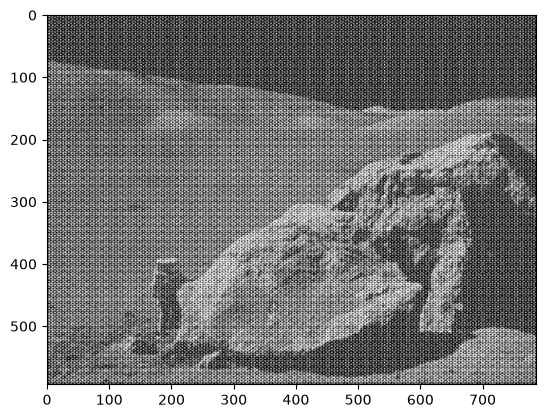

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('periodic_noise.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(img, cmap="gray")

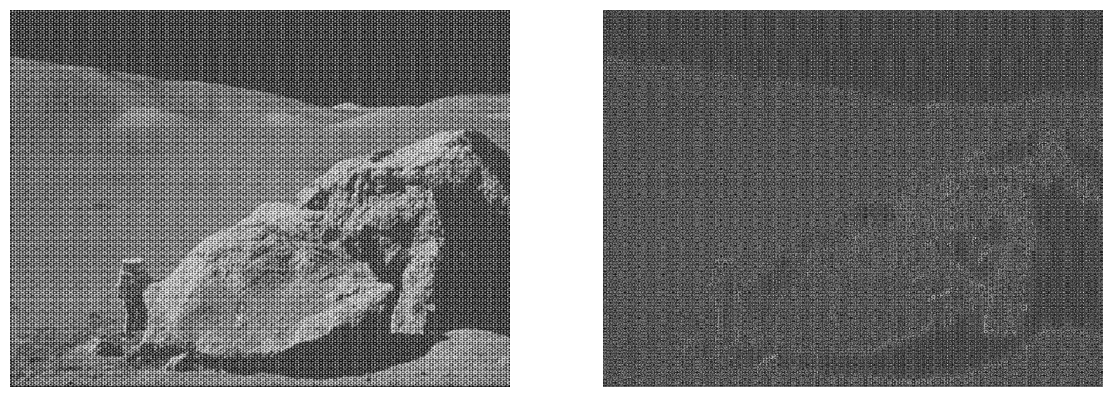

In [16]:
# Высокочастотный фильтр Гаусса
def gaussian_kernel(shape, sigma):
    rows, cols = shape
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    d2 = (y - crow)**2 + (x - ccol)**2
    kernel = np.exp(-d2 / (2.0 * sigma**2))
    return kernel

sigma = 10
low_filter  = gaussian_kernel(img.shape[:2], sigma)  

high_filter = 1.0 - low_filter

img_f = np.float32(img)     
dft = cv2.dft(img_f, flags=cv2.DFT_COMPLEX_OUTPUT)  
dft_shift = np.fft.fftshift(dft)  

filtered_shift = dft_shift * high_filter[:, :, np.newaxis]

f_ishift = np.fft.ifftshift(filtered_shift)
img_back = cv2.idft(f_ishift)
img_back = cv2.magnitude(img_back[:, :, 0], img_back[:, :, 1])

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1); plt.imshow(img, cmap='gray'); plt.axis('off')
plt.subplot(2, 2, 2); plt.imshow(img_back, cmap='gray');plt.axis('off')
plt.tight_layout(); plt.show()


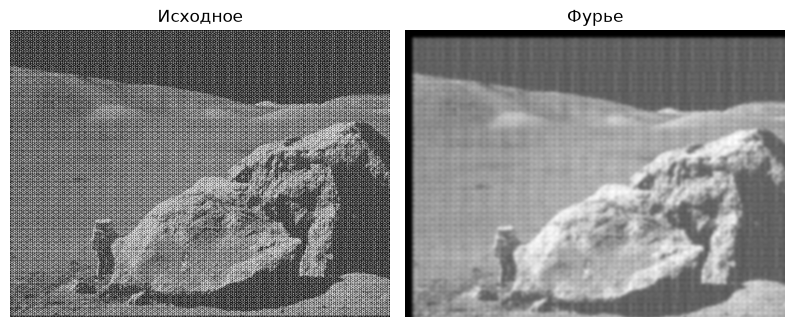

In [17]:
# Фурье
def fft_convolve(image, kernel):
    h = image.shape[0] + kernel.shape[0] - 1
    w = image.shape[1] + kernel.shape[1] - 1
    n = 1 << int(np.ceil(np.log2(max(h, w))))   
    img_p = np.zeros((n, n), np.float32)
    img_p[:image.shape[0], :image.shape[1]] = image.astype(np.float32)

    ker_p = np.zeros((n, n), np.float32)
    ker_p[:kernel.shape[0], :kernel.shape[1]] = kernel.astype(np.float32)

    res = np.real(np.fft.ifft2(np.fft.fft2(img_p) * np.fft.fft2(ker_p)))
    return res[:image.shape[0], :image.shape[1]]

ksize = 31
g1d = cv2.getGaussianKernel(ksize, 3.0)
g2d = np.outer(g1d, g1d)
g2d /= g2d.sum()

conv_fft = fft_convolve(img, g2d)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(img, cmap='gray'); plt.title('Исходное'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(np.clip(conv_fft, 0, 255).astype(np.uint8), cmap='gray')
plt.title('Фурье'); plt.axis('off')
plt.tight_layout(); plt.show()

found peaks: 376


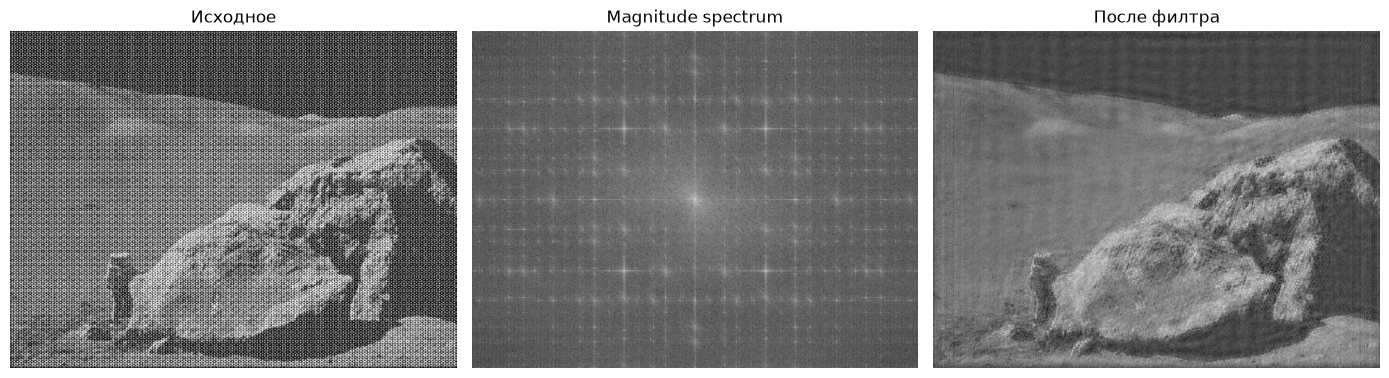

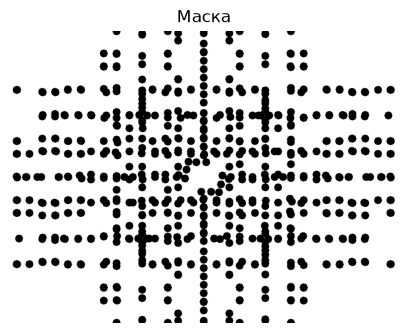

In [12]:
# Удаление периодического шума с помощью преобразования Фурье
f = np.fft.fft2(img.astype(np.float32))
fshift = np.fft.fftshift(f)
magnitude = 20 * np.log(np.abs(fshift) + 1)

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

notch_radius  = 8
center_radius = 30

spec = magnitude.copy()
spec[crow - center_radius:crow + center_radius,
    ccol - center_radius:ccol + center_radius] = 0

thr = np.percentile(spec, 99.5)
peaks = np.argwhere(spec > thr)

filtered_peaks = []
for (r, c) in peaks:
    if all((r - r2)**2 + (c - c2)**2 > (2 * notch_radius)**2
           for (r2, c2) in filtered_peaks):
        filtered_peaks.append((r, c))
print('found peaks:', len(filtered_peaks))

mask = np.ones((rows, cols), np.uint8)
yy, xx = np.ogrid[:rows, :cols]
for (r, c) in filtered_peaks:
    r_sym, c_sym = 2 * crow - r, 2 * ccol - c
    for (rr, cc) in [(r, c), (r_sym, c_sym)]:
        mask[(yy - rr)**2 + (xx - cc)**2 <= notch_radius**2] = 0


fshift_filtered = fshift * mask
img_back = np.real(np.fft.ifft2(np.fft.ifftshift(fshift_filtered)))

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1); plt.imshow(img, cmap='gray')
plt.title('Исходное'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(magnitude, cmap='gray')
plt.title('Magnitude spectrum'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(np.clip(img_back, 0, 255).astype(np.uint8), cmap='gray')
plt.title('После филтра'); plt.axis('off')
plt.tight_layout(); plt.show()

plt.figure(figsize=(5, 5))
plt.imshow(mask, cmap='gray'); plt.title('Маска'); plt.axis('off'); plt.show()